## Table of Contents

#### Part I: Research Question

A1. [Research Question](#A1.-Research-Question)

A2. [Goals](#A2.-Goals)

#### Part II: Method Justification

B1. [Summary of Assumptions](#B1.-Summary-of-Assumptions)

B2. [Tool Benefits](#B2.-Tool-Benefits)

B3. [Appropriate Technique](#B3.-Appropriate-Technique)

#### Part III: Data Preparation

C1. [Data Cleaning](#C1.-Data-Cleaning)

C2. [Summary Statistics](#C2.-Summary-Statistics)

C3. [Visualizations](#C3.-Visualizations)

C4. [Data Transformation](#C4.-Data-Transformation)

C5. [Prepared Data Set](#C5.-Prepared-Data-Set)

#### Part IV: Model Comparison and Analysis

D1. [Initial Model](#D1.-Initial-Model)

D2. [Justification of Model Reduction](#D2.-Justification-of-Model-Reduction)

D3. [Reduced Linear Regression Model](#D3.-Reduced-Linear-Regression-Model)

E1. [Model Comparison](#E1.-Model-Comparison)

E2. [Output and Calculations](#E2.-Output-and-Calculations)

E3. [Code](#E3.-Code)

#### Part V: Data Summary and Implications

F1. [Results](#F1.-Results)

F2. [Recommendations](#F2.-Recommendations)

#### Part VI: Sources


H. [Sources of Third-Party Code](#H.-Sources-of-Third-Party-Code)

I. [Sources](#I.-Sources)

### Part I: Research Question

#### A1. Research Question

For this performance assessment, I will be analyzing the Churn dataset, which contains customer data for an Internet Service Provider (ISP). The research question that will be addressed in this performance assessment is: "Which factors are correlated to customer bandwidth usage?" 

#### A2. Goals

The goal of this analysis is to determine which factors are correlated with customer bandwidth usage; this will be determined by utilizing the multiple linear regression method to determine which explanatory variables in the Churn dataset have a relationship with the response variable, Bandwidth_GB_Year. Understanding bandwidth usage could assist an ISP in a variety of ways, such as determining which customers will place heavier bandwidth loads on their infrastructure, or estimating bandwidth usage for a given region or customer group.

### Part II: Method Justification

#### B1. Summary of Assumptions 

There are four core assumptions when performing a multiple linear regression analysis:

1. A linear relationship exists between the explanatory and response variables. If the relationship is not linear, then a linear regression is not an appropriate analysis.
2. The residuals are normally distributed. This means that the errors between the observed and predicted values follow a normal distribution.
3. No multicolinearity exists between the explanatory variables. The explanatory variables are not strongly correlated with each other.
4. The data should show homoscedasticity. This means that the residuals - that is, the errors between the predicted and actual values of the response variable - have a constant variance across the linear model.

(Pennsylvania State University, 2018)

#### B2. Tool Benefits

I will be using Python to complete all steps in this analysis, including cleaning and wrangling the data, and performing the linear regression. Python is an open-source programming language that is very commonly used for data analytics and data science in both business and academia. As Python is an open-source tool, it is free to use, and therefore is more accessible than other pay-for-use tools such as SAS. (WGU School of Information Technology, n.d.) On a more personal level, I have more direct experience with using Python in both my academic and professional careers, which makes it a more appealing choice to me versus other free tools such as R.

Python features a number of useful packages and libraries that can be used in manipulating and analyzing data. One of the most widely-known and utilzied packages for this purpose is Pandas, which allows for the importation of data into objects called "dataframes." Pandas dataframes arrange data into a row/column structure that is extremely similar to spreadsheets, or tables in relational databases. It also features a number of functionalities to assist in addressing, modifying, and analyzing data stored within these dataframes. (Pandas Documentation, 2024) As the Churn file I will be using for this analysis is stored in a spreadsheet format, Pandas makes sense for this use case. 

Python can also make use of packages that allow for the creation of data visualizations. For this analysis, I'll be using the Seaborn package, which builds upon another commonly-used visualization package, Matplotlib. Seaborn was built to integrate closely with Pandas dataframes, making it well-suited for use in this analysis. (Seaborn Documentation, 2024)

For performing the multiple linear regression itself, I'll be importing the Statsmodels package, which is a package containing functionality for applying a large number of statistical models and performing various statistical tests. For this specific analysis, I'll be using the statsmodels.api.OLS function, which allows for the creation of a multiple linear regression model when passed the relevant columns from a dataframe. (Statsmodels Documentation, 2023)


#### B3. Appropriate Technique

Multiple Linear Regression (MLR) is a statistical technique that allows for an analyst to determine whether a linear relationship exists between multiple explanatory variables and a single continuous response variable. (Pennsylvania State University, 2024) The goal of this analysis, as stated above, is to determine which variables in the Churn dataset correlate with bandwidth usage, as represented by the response variable Bandwidth_GB_Year.

MLR is a suitable analytic technique for this use case, as our goal is to determine whether a relationship exists between multiple explanatory variables, and a single continuous response  variable. By producting a reduced MLR model, we'll be able to see which variables have a linear relationship with Bandwidth_GB_Year, and to what extent changes to these explanatory variables affect bandwidth usage.

### Part III: Data Preparation

#### C1. Data Cleaning

Before performing the analysis, it is necessary to inspect the dataset for issues and address them where possible. As with any type of statistical analysis, multiple linear regression relies on clean, trustworthy, and useable data in order to produce reliable results. 

The first step in cleaning the data will involve identifying and dropping duplicate records; each row in the dataset should represent a single customer, so that repeated data does not skew the analytics results. This will involve looking both for complete duplicate records that share data across all columns, as well as records that contain duplicate data in specific columns that are meant to be unique (specifically, these are Customer_id and Interaction). 

Next, I'll check for missing or malformed data across all columns. Data that is missing, incorrectly formatted, or data that falls outside of expected values (e.g., data other than "Yes" or "No" in a column defined as having only Yes or No as possible responses) could indicate deeper issues with the data for that row.

The final data cleaning step will involve the identification of outliers in the relevant continuous variables that will be used in the analysis: Bandwidth_GB_Year, Population, Tenure, and Outage_sec_perweek. Outliers could introduce skewness into the distributions for these variables, and could also a disproportionate affect on the multiple linear regression analysis we perform later. Values within these columns will be compared against the third and first quartiles, as well as the interquartile range; in cases where the values are far outside of these ranges, the entire row will be dropped.

The goal with these data cleaning steps is to ensure that the data used to build the initial multiple linear regression model is accurate, and not skewed or disrupted by outliers, missing data, or incorrectly formatted fields.

In [1]:
# Import necessary packages
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib as plt

# Import the dataset
churnfile = pd.read_csv('../data/churn_clean.csv',index_col=0, keep_default_na=False, na_values=['NA'])  # 'None' is a valid InternetService value

# Data quality check: Find complete dupes
churnfile_compldupes = churnfile.duplicated()
print("Complete dupes: " + str(churnfile_compldupes.any()))

# Data quality check: Look for dupes on columns that should be unique
uniquecols = ['Customer_id','Interaction']
for cols in (uniquecols):
    churnfile_uniqdupes = churnfile.duplicated(subset=cols, keep=False)
    print("Dupes in column " + cols + ": " + str(churnfile_uniqdupes.any()))

# Data quality check: Look for missing data
missingcols = []
for cols in churnfile:
    if ((churnfile[cols].isnull().sum()) > 0):
        missingcols.append(cols)
if len(missingcols) > 0:
    print("Columns that are missing data: ")
    print(missingcols)
else:
    print("No missing data found")

# Data quality check: Find non-boolean values in boolean vars
boolvars = ['Churn','Techie','Port_modem','Tablet','Phone','Multiple',
            'OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport',
            'StreamingTV','StreamingMovies','PaperlessBilling']
badbools = []
for col in boolvars:
    if churnfile[col][~churnfile[col].isin(["Yes","No"])].any() == True:
        badbools.append(col)
if len(badbools) > 0:
    print("Boolean columns that have out-of-range values: ")
    print(badbools)
else:
    print("No invalid boolean values found")        
    
# Data quality check: Find invalid categorical values
rangecols = {"Gender":['Male','Female','Nonbinary'],
             "Marital":['Married','Separated','Divorced','Never Married','Widowed'],
             "Area":["Rural","Urban","Suburban"],
             "Contract":["One year","Two Year","Month-to-month"],
             "InternetService":["Fiber Optic","DSL","None"],
             "PaymentMethod":["Bank Transfer(automatic)","Credit Card (automatic)",
                              "Electronic Check","Mailed Check"]
            }
badrange = []
for col, val in rangecols.items():
    if churnfile[col][~churnfile[col].isin(val)].any() == True:
        badrange.append(col)
if len(badrange) > 0:
    print("Categorical columns that have invalid values: ")
    print(badrange)
else:
    print("No invalid categorical values found")
    

# Find and remove outliers
# Bandwidth_GB_Year
# Outage_sec_perweek
# Population
# Tenure

for col in ['Bandwidth_GB_Year','Outage_sec_perweek','Population','Tenure']:
    Q3 = np.percentile(churnfile[col], 75)
    Q1 = np.percentile(churnfile[col], 25)
    
    IQR = (Q3-Q1)
    
    lowerlimit = Q1-(1.5*IQR)
    upperlimit = Q3+(1.5*IQR)
    
    churnfile.drop(churnfile[churnfile[col] > upperlimit].index, inplace=True)
    churnfile.drop(churnfile[churnfile[col] < lowerlimit].index, inplace=True)
    
    print("Outliers removed for " + col)

Complete dupes: False
Dupes in column Customer_id: False
Dupes in column Interaction: False
No missing data found
No invalid boolean values found
No invalid categorical values found
Outliers removed for Bandwidth_GB_Year
Outliers removed for Outage_sec_perweek
Outliers removed for Population
Outliers removed for Tenure


#### C2. Summary Statistics

Descriptive statistics for the response variable, Bandwidth_GB_Year, are included below. This continuous variable is a measure of the annual bandwidth usage, in gigabytes, for each customer. Across all 8889 records, the values in this column range from 155.50 gigabytes on the low end, up to 7158.98 gigabytes on the high end. The average bandwidth used in a year is 3403.03 gigabytes; the median is 3419.03 gigabytes. 

Summary statistics for the explanatory variables have also been printed below; these variables are Area, Yearly_equip_failure, Techie, Contract, Port_modem, Tablet, InternetService, Phone, Multiple, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Outage_sec_perweek, Population, and Tenure.

Area is a categorical variable with three possible values: Rural, Suburban, and Urban. Total counts for these values are relatively close across the datatset: there are 2988 Rural records, 3001 Suburban, and 3010 Urban.

Yearly_equip_failure is a numeric variable showing the total number of equipment failures the customer has suffered in a given year. The values range from 0 to 6. The vast majority of customers - 6058 out of the 8999 in the dataset - have never had an equipment failure, and have a value of 0 in this column. The number of customers dwindles as the count of equipment failures rises: 2393 customers have had 1 failure, 464 have had 2, 77 have had 3, 6 have had 4, and just 1 has had 6 failures. No customers have had 5 failures. The average for this column is around 0.39 yearly failures, and the median is 0.

Techie is a boolean column with valid values of Yes and No. This column indicates whether the customer is technically capable. Most customers do not feel they are techies; 7480 records have a No for this column, with 1519 answering yes.

Contract is a categorical variable indicating the type of service contract the customer has with the ISP. Valid values are Month-to-month, Two Year, and One Year. 4924 customers have a month to month contract; 2168 have a two year contract; and 1907 have a one year contract.

Port_modem is a boolean column with valid values of Yes and No. This field indicates whether or not the customer has a portable modem. 4657 records do not have a portable modem; 4342 do have one.

Tablet is a boolean column with valid values of Yes and No. This indicates whther a customer has a tablet. 6293 records show no tablet; 2706 do have a tablet.

InternetService is a categorical variable indicating the type of internet service the customer has. Valid values for this column are Fiber Optic, DSL, and None. 3970 records show Fiber Optic; 3113 have DSL; 1916 have None.

Phone is a boolean column with valid values of Yes and No. This field indicates whether a customer has home phone service. The overwhelming majority of customers do have phone service, with 8162 records showing a Yes in this column; just 837 have no phone.

Multiple is a boolean column with valid values of Yes and No. This column shows whether or not a customer has multiple phone lines. 4842 customers have a No in this column while 4157 have a Yes.

OnlineSecurity is a boolean column with valid values of Yes and No. This shows whether or not a customer subscribes to the ISP's online security add-on package. 5782 customers do not have this add-on; 3217 do have it.

OnlineBackup is a boolean column with valid values of Yes and No. This indicates whether the customer subscribes to the ISPs online data backup add-on package. 4948 records show a value of No; 4051 records have a value of Yes.

DeviceProtection is a boolean column with valid values of Yes and No. This column indicates whether the customer subscribes to the ISP's device protection plan. 5050 records show No; 3949 records show Yes.

TechSupport is a boolean column with valid values of Yes and No. The column shows whether the customer subscribes to the ISP's tech support add-on plan. 5625 customers do not subscribe to this plan; 3374 do subscribe to it.

StreamingTV is a boolean column with valid values of Yes and No. This shows whether or not the customer subscribes to the ISP's streaming television add-on package. 4554 records show the customer does not subscribe to the streaming TV service; 4445 records show that the customer does subscribe to it.

StreamingMovies is a boolean column with valid values of Yes and No. This shows whether the customer subscribes to the ISP's movie streaming add-on service. 4564 records show a value of No; 4435 records show a value of Yes.

Outage_sec_perweek is a continuous variable that is a measure of the average amount of seconds per week that a customer has suffered a service outage. The average for this value is 9.99 seconds; the range is from 2.09 seconds at the lowest end, all the way up to 17.86 seconds at the highest. The median is 10 seconds.

Population is a continuous variable showing the total population within a mile radius of the customer's residence. The values in this column range from 0 to 31860. The average is 6039.47, and the median is 2275.

Tenure is a continuous variable showing the number of months that the customer has actively been subscribed with the ISP. The lowest value in this column is 1 month; the highest value is 71.99 months. The average customer tenure is 34.64 months, and the median is 37.04 months. 

In [2]:
# Print descriptive statistics for Outage_sec_perweek
print("Descriptive statistics for the response variable, Bandwidth_GB_Year:")
print(churnfile['Bandwidth_GB_Year'].describe())
print("\n")


# Print descriptive statistics for explanatory vars
explan_vars = ["Area","Yearly_equip_failure","Techie","Contract","Port_modem","Tablet",
               "InternetService","Phone","Multiple","OnlineSecurity","OnlineBackup",
               "DeviceProtection","TechSupport","StreamingTV","StreamingMovies","Outage_sec_perweek",
               "Population","Tenure"]

print("Descriptive statistics for explanatory variables:")
print("\n")
for var in explan_vars:
    print("Statistics for " + var)
    print(churnfile[var].describe())
    print(churnfile[var].value_counts())
    print("\n")

Descriptive statistics for the response variable, Bandwidth_GB_Year:
count    8999.000000
mean     3403.032287
std      2184.473515
min       155.506715
25%      1238.368638
50%      3419.036940
75%      5593.110247
max      7158.981530
Name: Bandwidth_GB_Year, dtype: float64


Descriptive statistics for explanatory variables:


Statistics for Area
count      8999
unique        3
top       Urban
freq       3010
Name: Area, dtype: object
Area
Urban       3010
Suburban    3001
Rural       2988
Name: count, dtype: int64


Statistics for Yearly_equip_failure
count    8999.000000
mean        0.398044
std         0.636747
min         0.000000
25%         0.000000
50%         0.000000
75%         1.000000
max         6.000000
Name: Yearly_equip_failure, dtype: float64
Yearly_equip_failure
0    6058
1    2393
2     464
3      77
4       6
6       1
Name: count, dtype: int64


Statistics for Techie
count     8999
unique       2
top         No
freq      7480
Name: Techie, dtype: object
Techie
No

#### C3. Visualizations

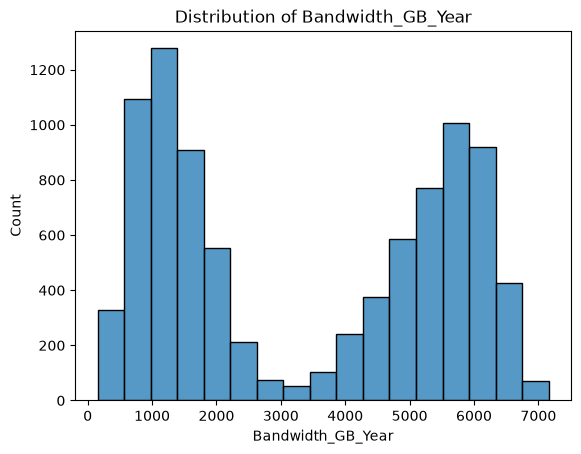

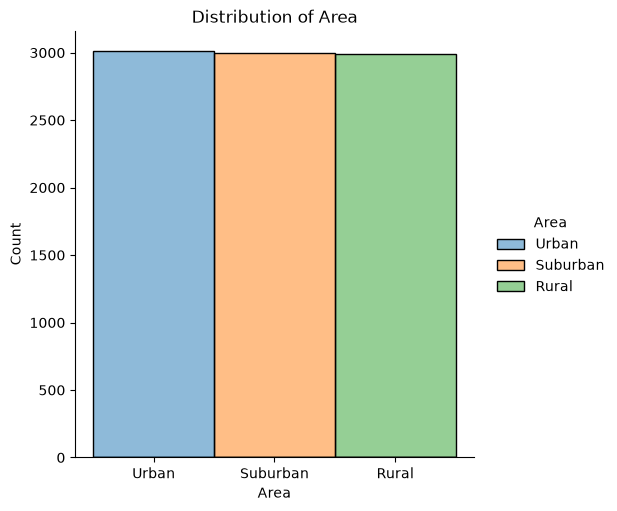

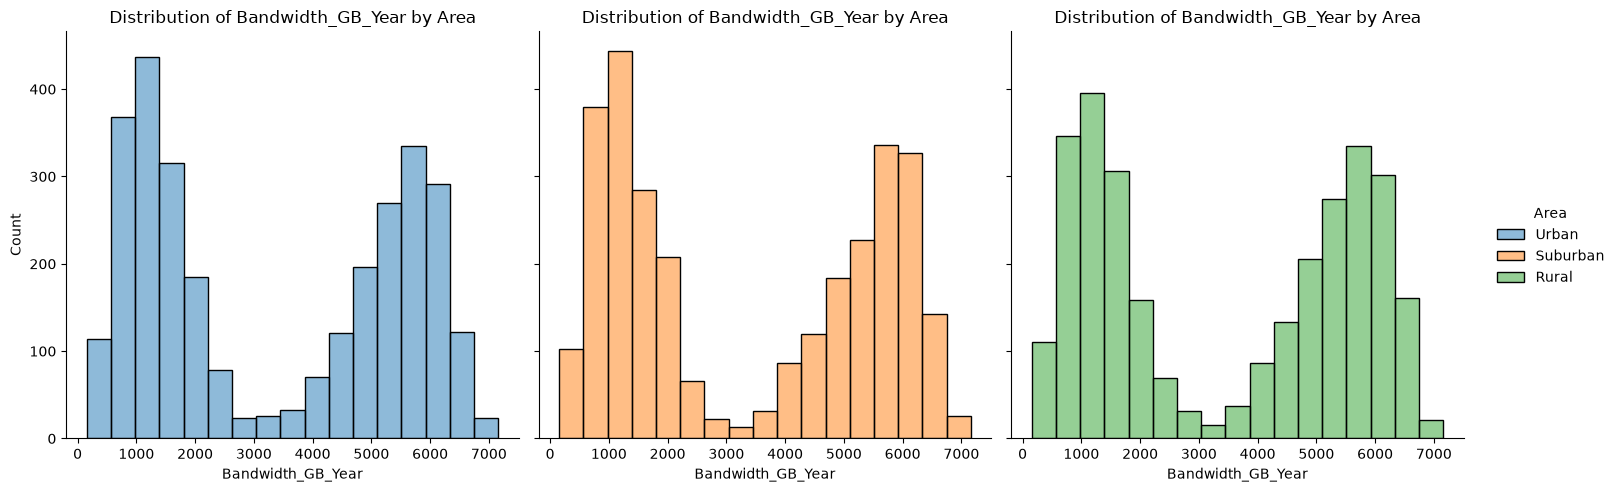

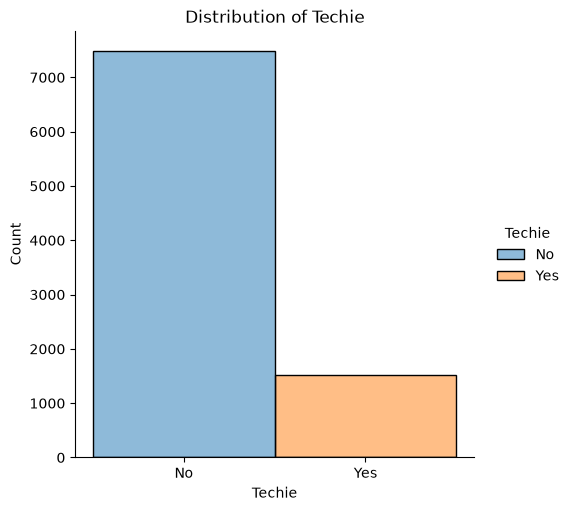

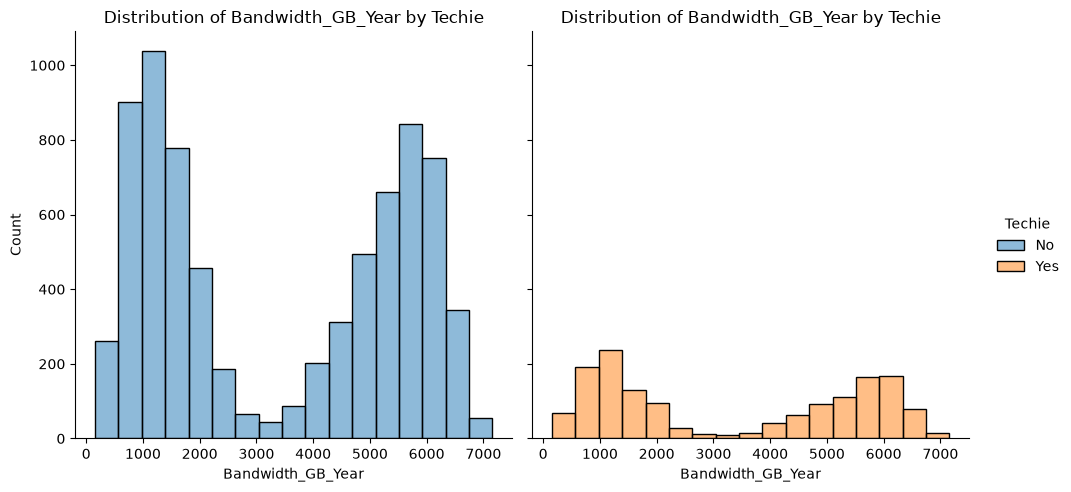

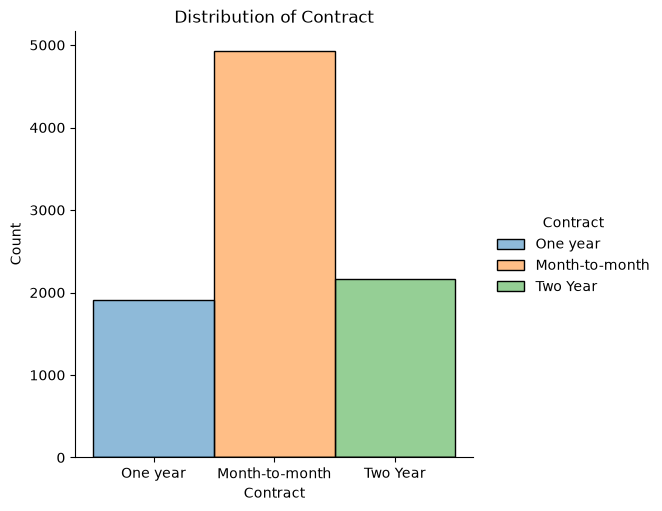

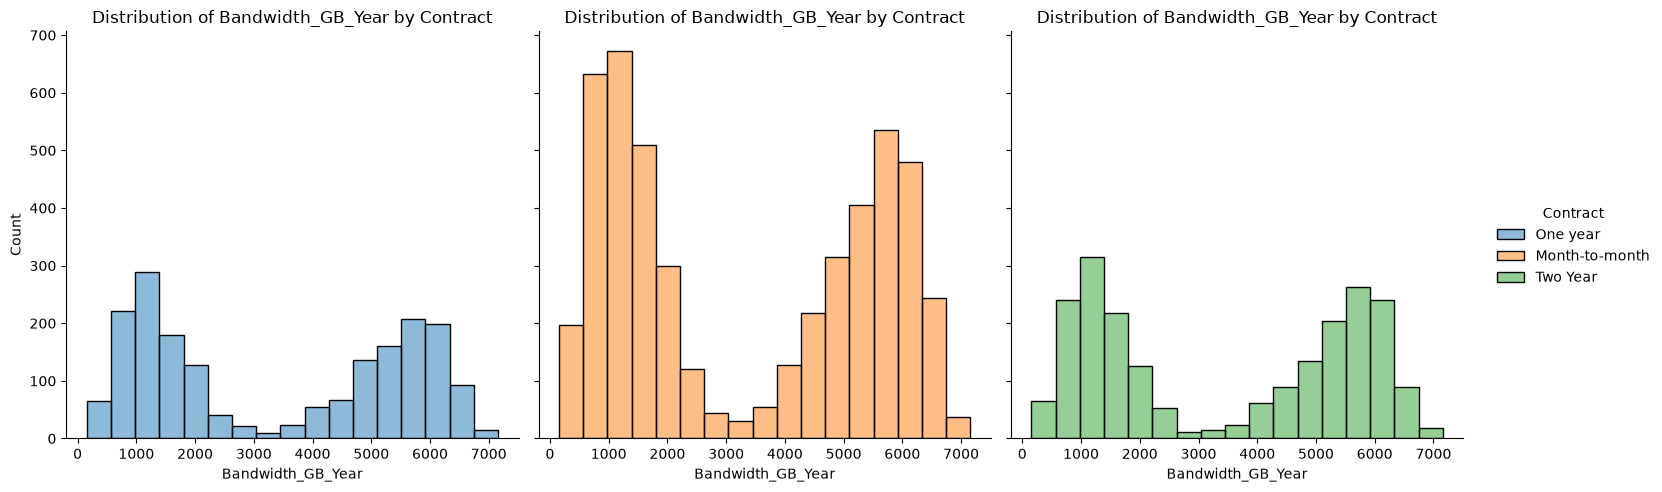

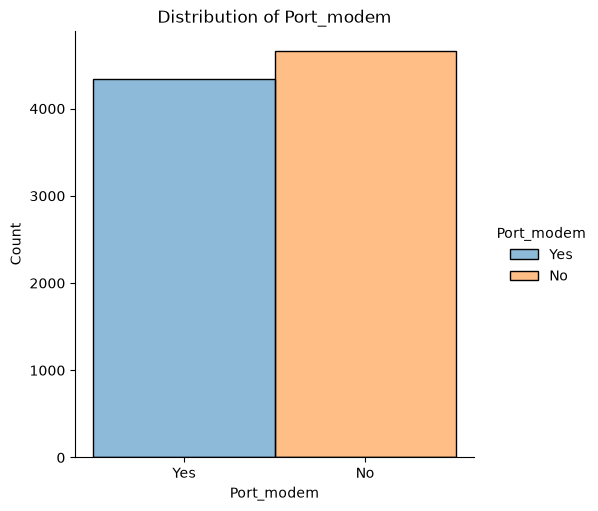

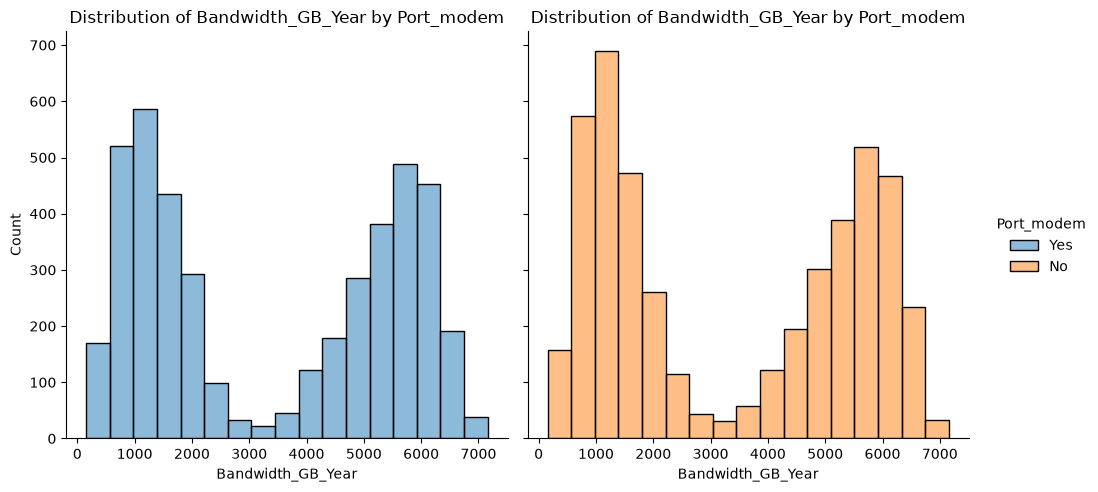

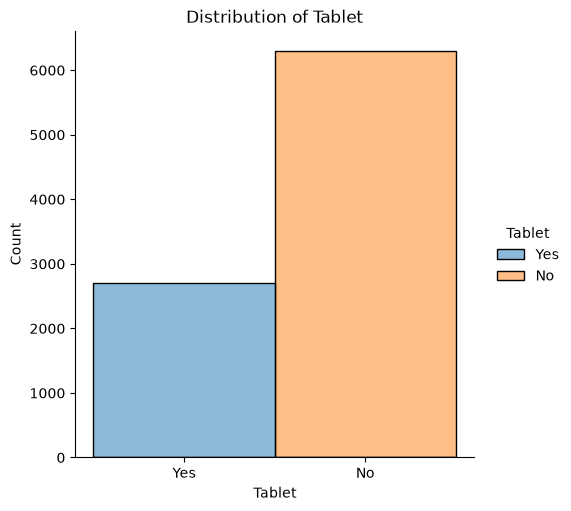

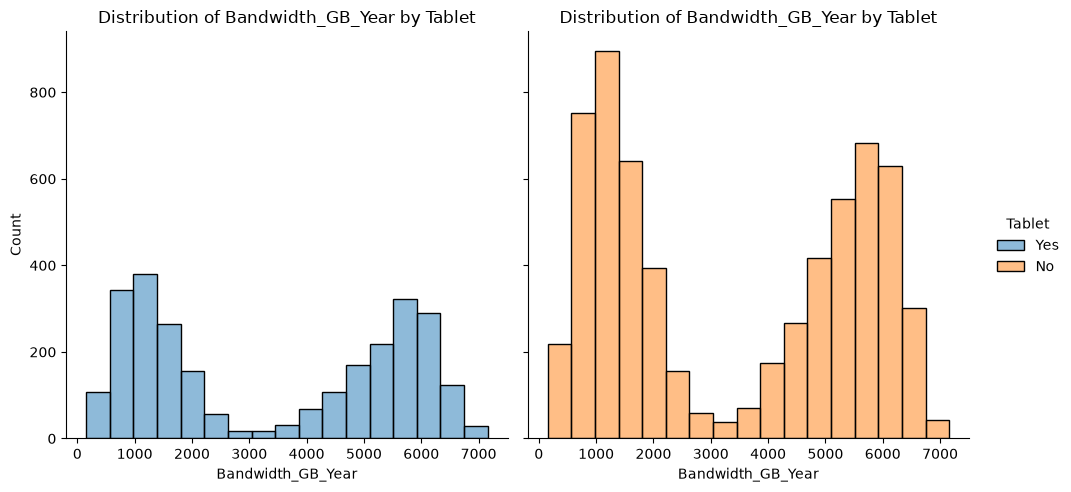

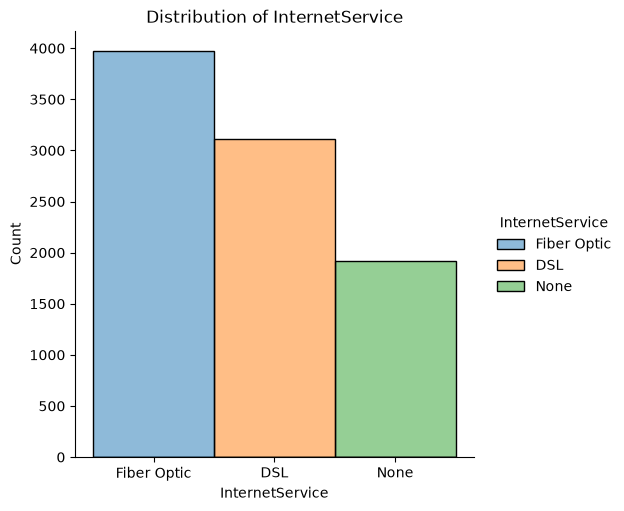

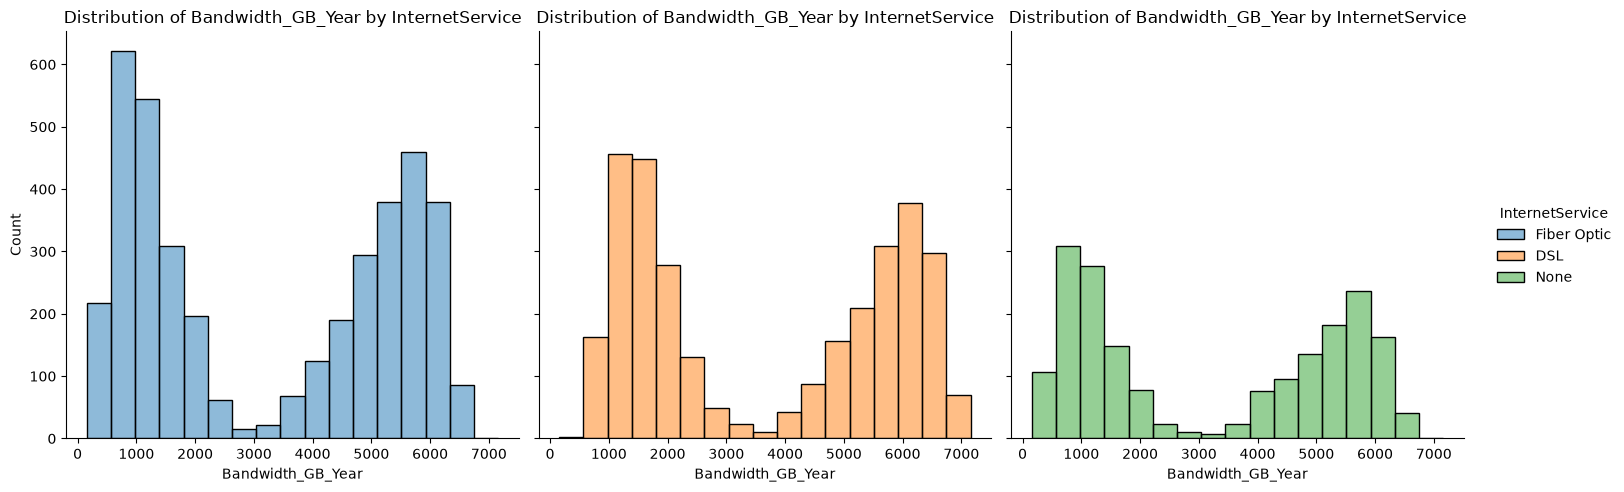

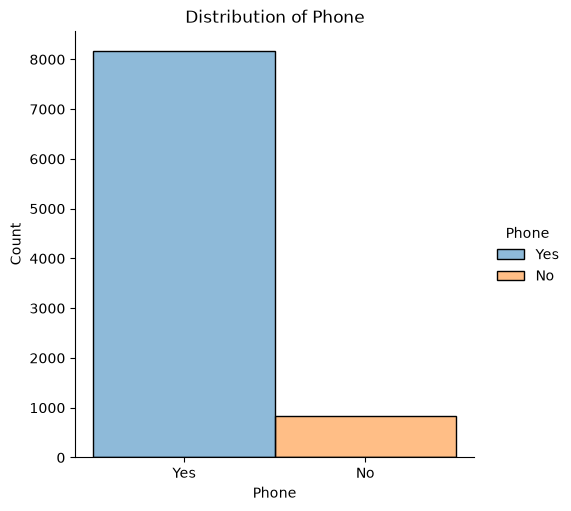

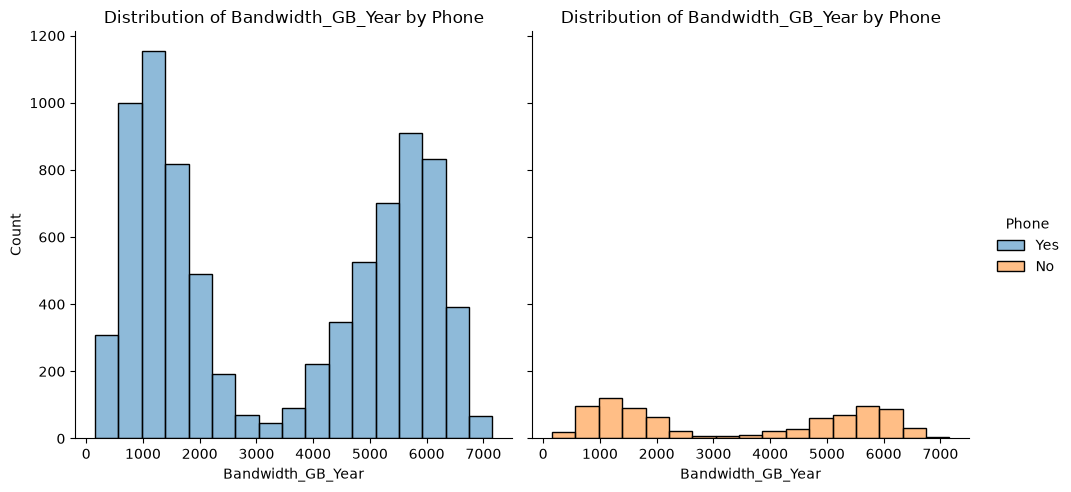

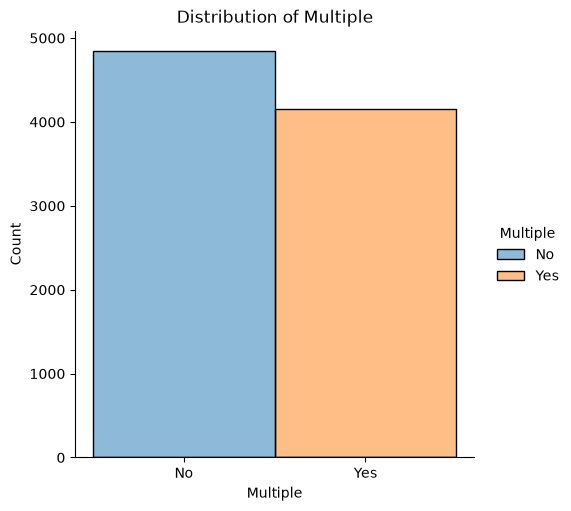

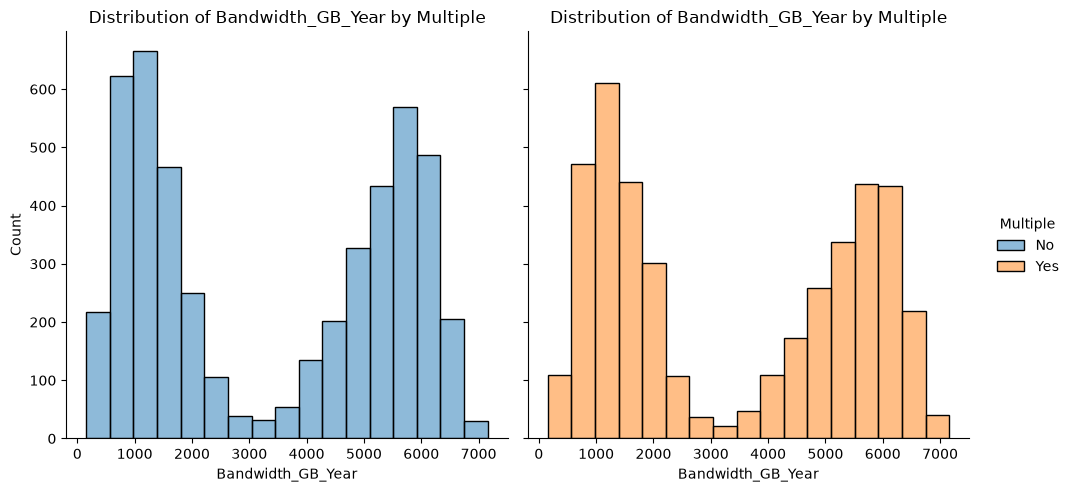

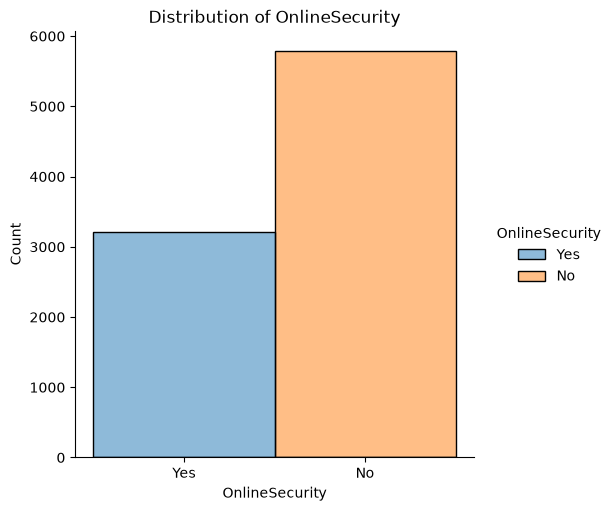

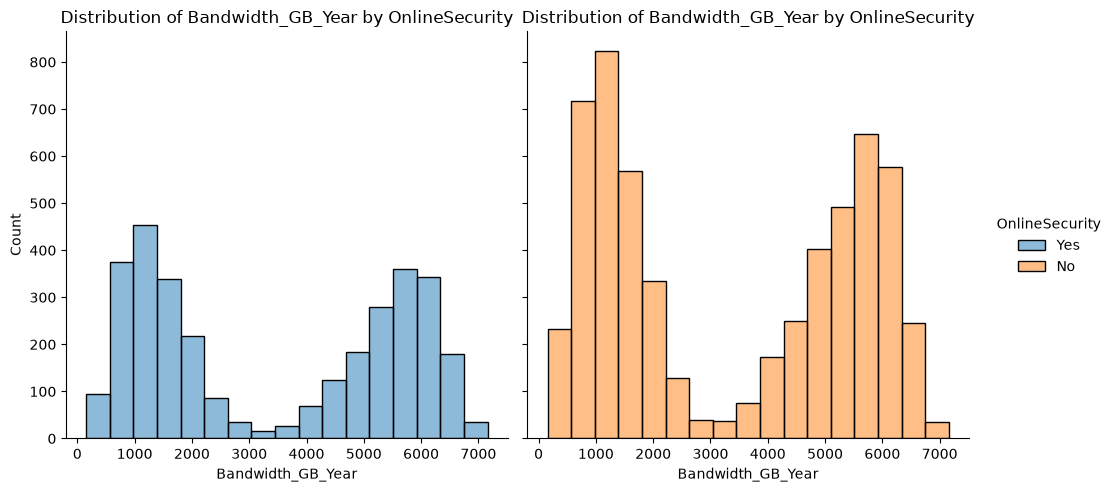

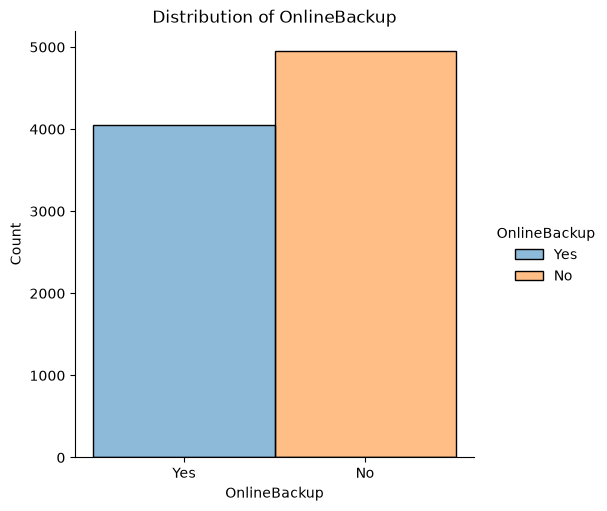

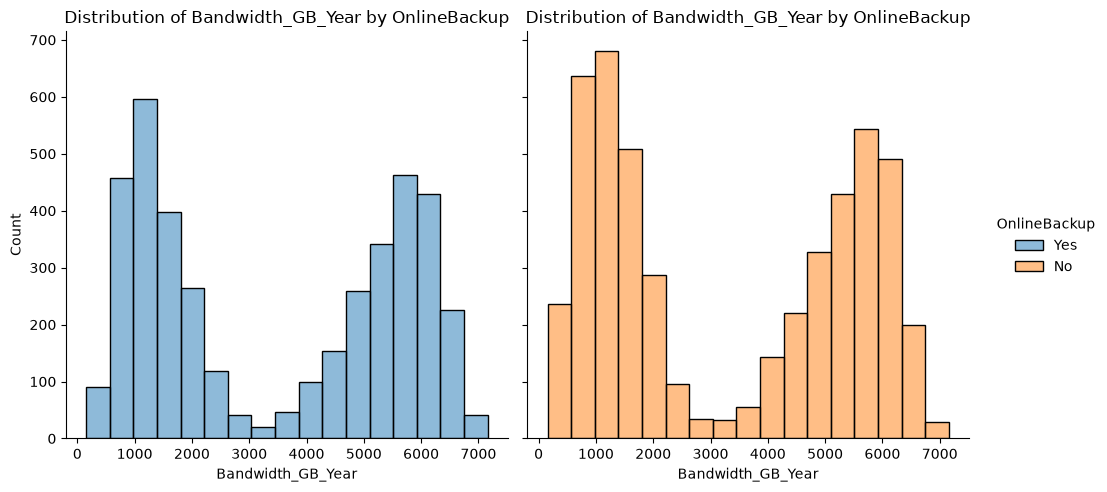

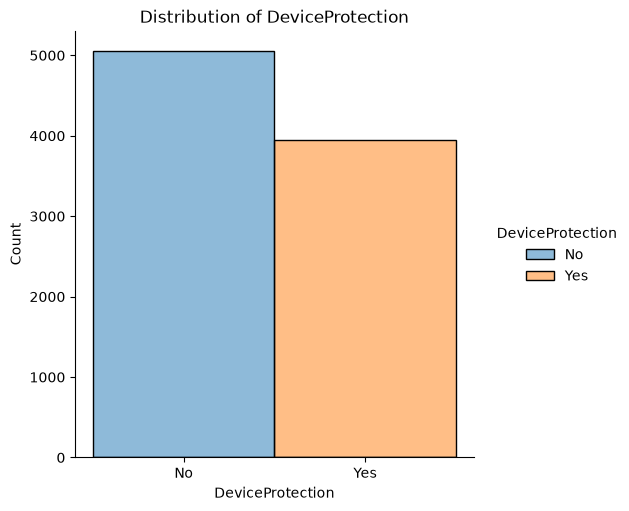

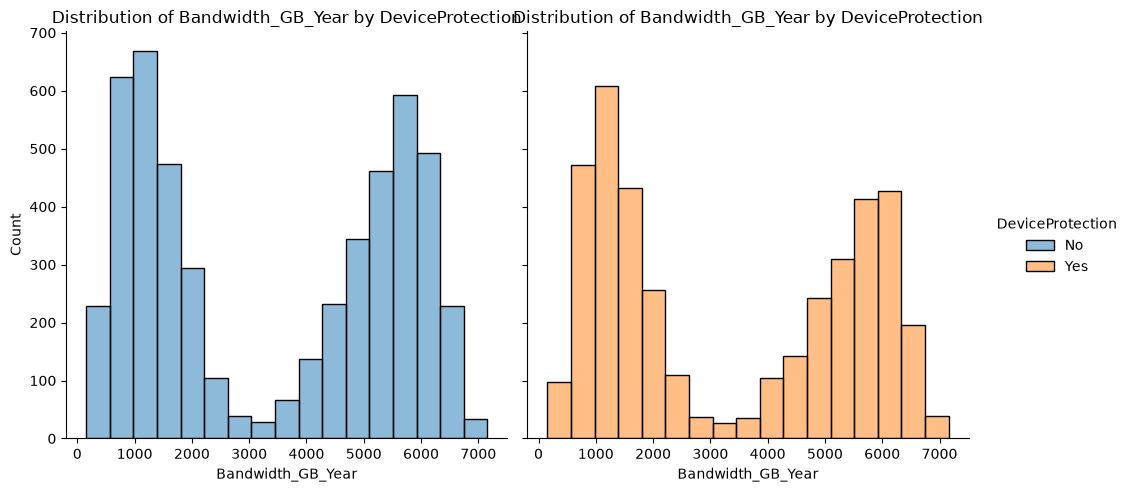

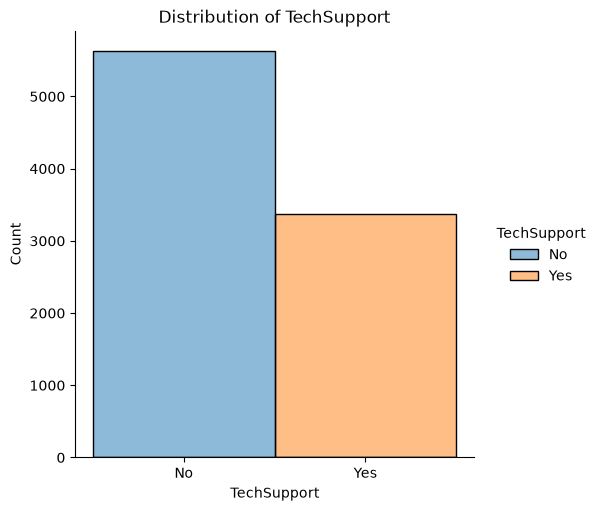

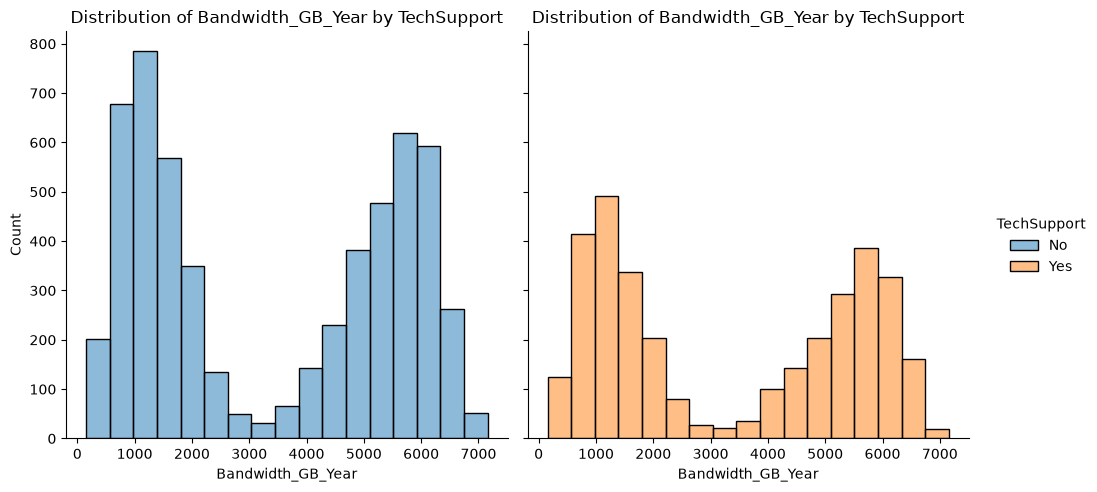

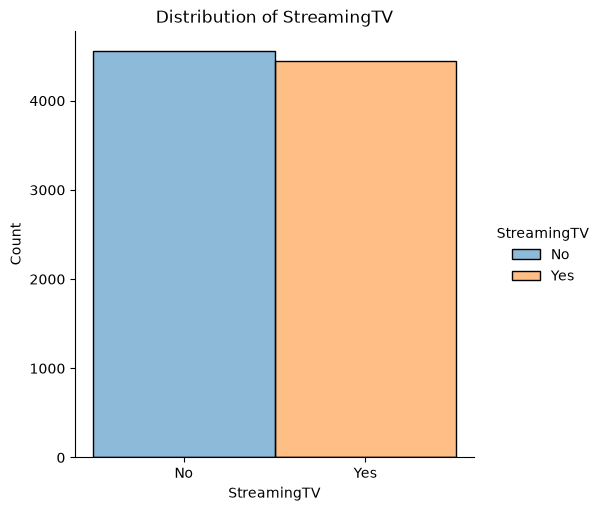

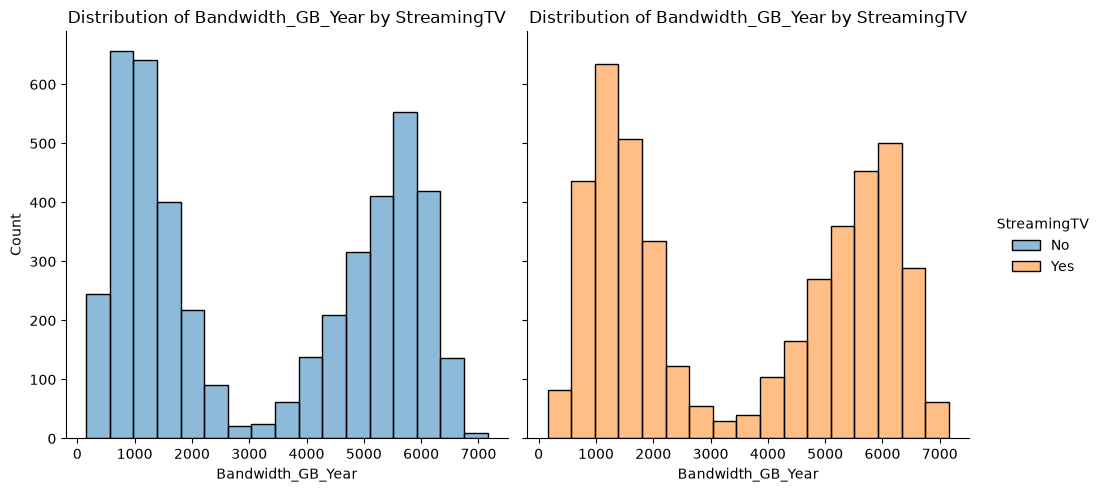

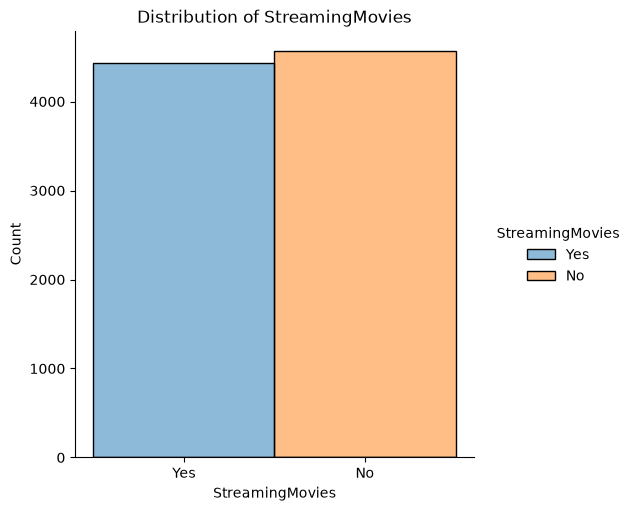

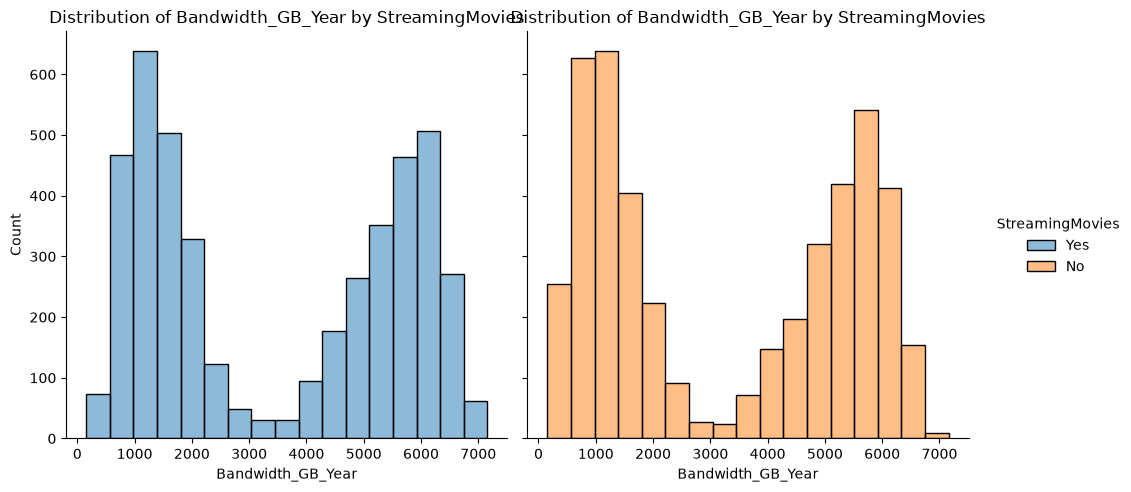

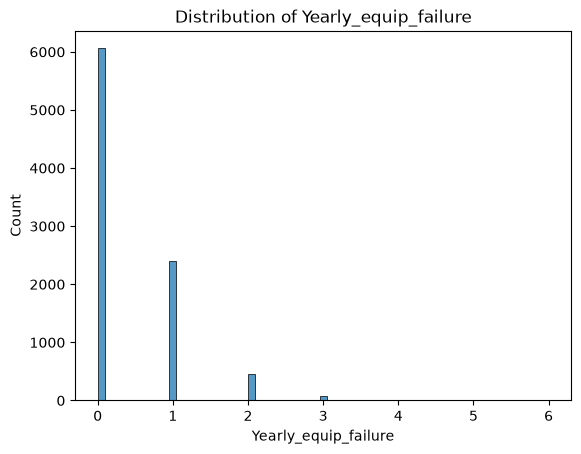

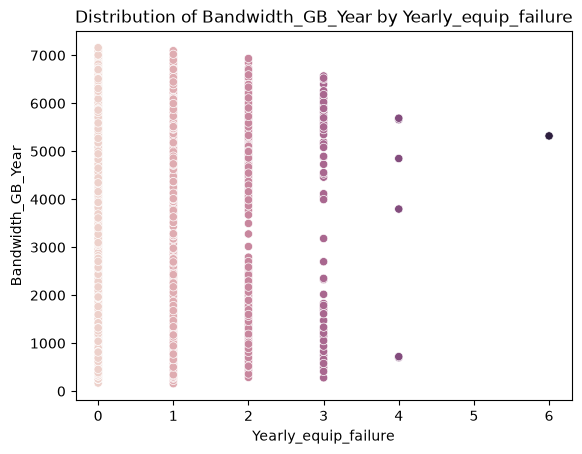

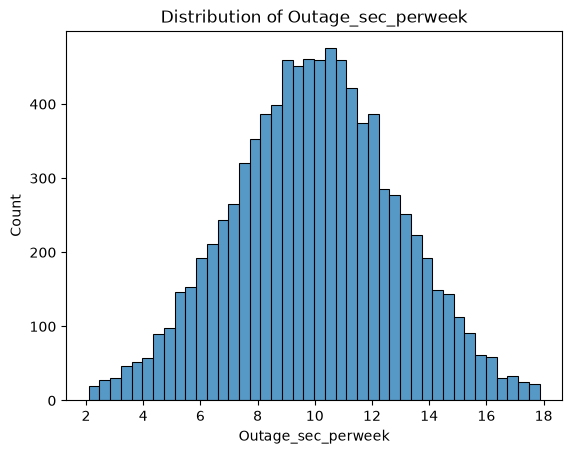

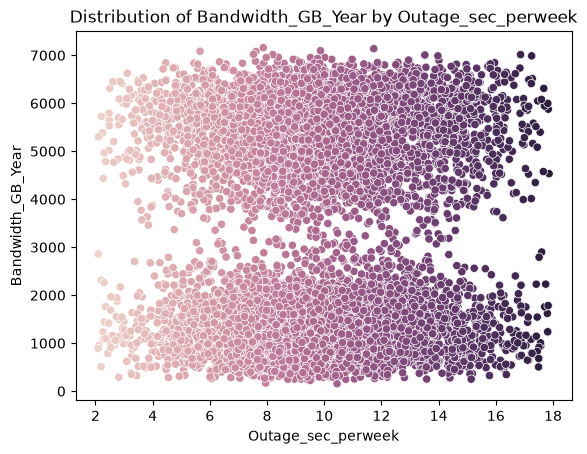

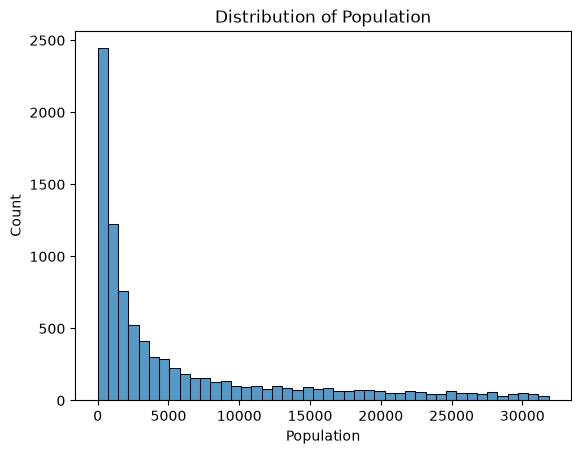

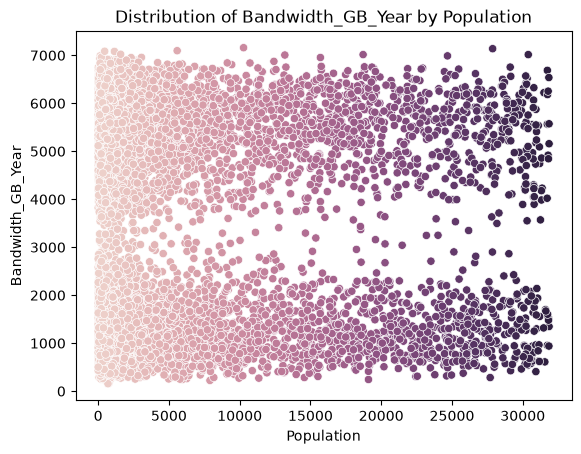

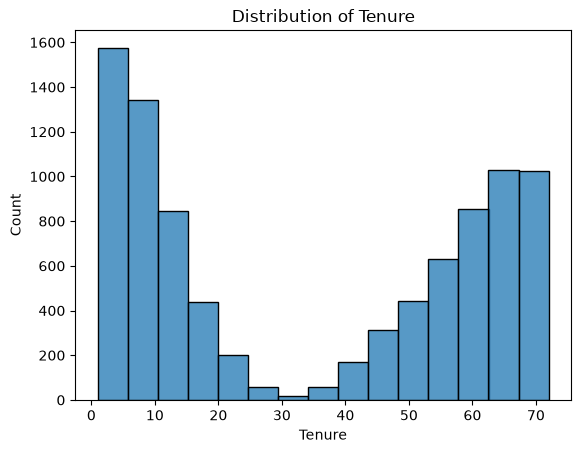

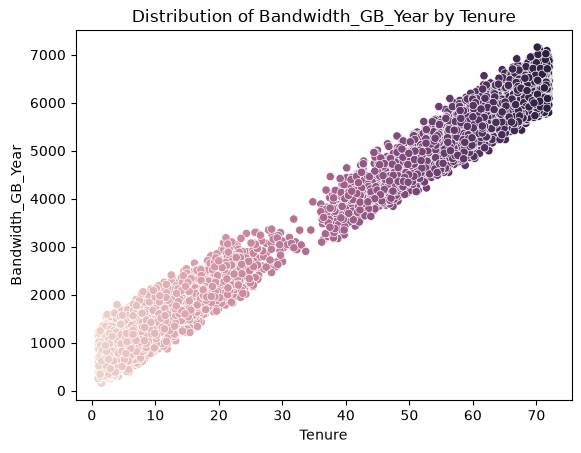

In [3]:
#Univariate and Bivariate Visualizations

explan_var_cat = ["Area","Techie","Contract","Port_modem","Tablet",
                  "InternetService","Phone","Multiple","OnlineSecurity","OnlineBackup",
                  "DeviceProtection","TechSupport","StreamingTV","StreamingMovies"]

explan_var_cont = ["Yearly_equip_failure","Outage_sec_perweek","Population","Tenure"]

# Distribution of response variable, Bandwidth_GB_Year
sns.histplot(data=churnfile, x='Bandwidth_GB_Year').set(title="Distribution of Bandwidth_GB_Year")
plt.pyplot.show()

# Univariate and Bivariate distributions of categorical explanatory variables
for var in explan_var_cat:
    sns.displot(data=churnfile, x=var,hue=var).set(title="Distribution of " + var)
    sns.displot(data=churnfile, x='Bandwidth_GB_Year', hue=var, col=var).set(title="Distribution of Bandwidth_GB_Year by " + var)
    plt.pyplot.show()

# Univariate and Bivariate distributions of continuous explanatory variables
for var in explan_var_cont:
    sns.histplot(data=churnfile, x=var, legend=False).set(title="Distribution of " + var)
    plt.pyplot.show()
    sns.scatterplot(data=churnfile, x=var, y='Bandwidth_GB_Year', hue=var, legend=False).set(title="Distribution of Bandwidth_GB_Year by " + var)
    plt.pyplot.show()

#### C4. Data Transformation

Before creating the multiple linear regression model, it is necessary to perform data transformation steps to prepare the data for modeling. First, all boolean categorical variables will be changed from Yes or No to values of 1 or 0, respectively, so that they can be included in the analysis itself. This will be done with the boolean variables Churn, Techie, Port_modem, Tablet, Phone, Multiple, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, and PaperlessBilling.

Categorical variables will also be modified using one-hot encoding; this involves replacing a single categorical column with new boolean columns for each potential value of the originating categorical column. K-1 encoding will be used to prevent multicolinearity; this involves creating one less column, and instead indicating that specific value by populating each of the other columns with zeroes. For example, the explanatory variable "Contract" has three potential values: One Year, Two Year, and Month-by-Month. Two new boolean columns, "Contract_One year" and "Contract_Two Year", will be created instead; a value of 1 in either field will indicate what type of contract the customer has. Values of zeroes in both fields will indicate a Month-by-Month contract type. One-hot encoding will be used for the Area, Contract, and InternetService columns.

Finally, a dataset will be created containing only the variables required for the creation of the multiple linear regression model. This includes all explanatory variables used in the analysis, which are listed above, along with the response variable, Bandwidth_GB_Year. A very wide net has been cast when selecting the explanatory variables for the initial model; the goal is to construct an inital model with the widest possible array of potential explanatory variables, and then improve that model by reducing it to contain only the most statistically significant explanatory variables.

In [4]:
# Convert Yes/No String Values to Numeric 1/0
for var in boolvars:
    churnfile[var] = churnfile[var].replace({"No": 0, "Yes": 1})

# Use One-Hot Encoding to Convert Categorical Variables to Numeric
# drop_first = True for k-1
churn_ohe = pd.get_dummies(churnfile, prefix="Area", columns=["Area"], drop_first=True, dtype=int)         
churn_ohe = pd.get_dummies(churn_ohe, prefix="Contract", columns=["Contract"], drop_first=True, dtype=int)     

# Apply OHE to InternetService separately so that values of None are mapped to all zeroes
# Without this the output OHE columns are Fiber Optic and None; for readability we prefer DSL and FiberOptic
InternetService_ohe = pd.get_dummies(churn_ohe["InternetService"], dtype=int).drop('None', axis=1)

# Append InternetService_ohe to churn_ohe
churn_appended = pd.concat([churn_ohe,InternetService_ohe],axis=1)

# Grab only the columns we need for initial MLR
churn_regress_initial = churn_appended[["Area_Suburban","Area_Urban","Yearly_equip_failure","Techie","Contract_One year",
                                        "Contract_Two Year","Port_modem","Tablet","Fiber Optic","DSL","Phone","Multiple",
                                        "OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV",
                                        "StreamingMovies","Bandwidth_GB_Year","Outage_sec_perweek","Population","Tenure"]]

print(churn_regress_initial)

           Area_Suburban  Area_Urban  Yearly_equip_failure  Techie  \
CaseOrder                                                            
1                      0           1                     1       0   
2                      0           1                     1       1   
3                      0           1                     1       1   
4                      1           0                     0       1   
5                      1           0                     1       0   
...                  ...         ...                   ...     ...   
9994                   0           0                     0       1   
9995                   0           1                     0       0   
9996                   0           0                     0       0   
9998                   0           0                     0       0   
10000                  0           1                     0       0   

           Contract_One year  Contract_Two Year  Port_modem  Tablet  \
CaseOrder         

After performing the necessary data transformation steps, I will address multicolinearity within the dataset. Multicolinearity exists when two or more of the explanatory variables have moderate-to-high levels of correlation; in such a scenario, adjustments to one explanatory variable could directly affect another variable. As the point of a linear regression test is to determine the effects of each explanatory variable on the response variable independently, having high levels of correlation between two or more explanatory variables could negatively affect the quality and reliability of the outcome of the analysis. (Pennsylvania State University, 2024)

To check for multicolinearity, I'll be using the variance inflation factor (VIF), which is a measure of the strength of correlation between the explanatory variables. Statsmodels has a function, variance_inflation_factor, which will be used for this purpose. Variance_inflation_factor function returns a VIF number for each variable. A value of 1 indicates no correlation; higher VIF levels indicate increasing levels of correlation. It is generally accepted that values above 5 indicate a high level of multicolinearity. (Bobbitt, 2022) Any explanatory variables that return a value above 5 will be dropped from the dataset used for the regression analysis. 

In [5]:
# Check for multicolinearity
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif

VIF_explan_vars = churn_regress_initial[["Area_Suburban","Area_Urban","Yearly_equip_failure","Techie","Contract_One year",
                                        "Contract_Two Year","Port_modem","Tablet","Fiber Optic","DSL","Phone","Multiple",
                                        "OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV",
                                        "StreamingMovies","Population","Tenure","Outage_sec_perweek"]]
               
vif_df = pd.DataFrame()
vif_df["feature"] = VIF_explan_vars.columns

vif_df["VIF"] = [vif(VIF_explan_vars, i) for i in range(len(VIF_explan_vars.columns))]

print(vif_df)

                 feature       VIF
0          Area_Suburban  1.928485
1             Area_Urban  1.926923
2   Yearly_equip_failure  1.378855
3                 Techie  1.196743
4      Contract_One year  1.373739
5      Contract_Two Year  1.427145
6             Port_modem  1.889892
7                 Tablet  1.424201
8            Fiber Optic  2.824680
9                    DSL  2.428874
10                 Phone  7.934833
11              Multiple  1.827639
12        OnlineSecurity  1.542210
13          OnlineBackup  1.782261
14      DeviceProtection  1.752833
15           TechSupport  1.571804
16           StreamingTV  1.930978
17       StreamingMovies  1.935684
18            Population  1.567872
19                Tenure  2.606963
20    Outage_sec_perweek  9.094427


It appears that the Phone and Outage_sec_perweek variables both have relatively high VIF values, at 6.701916 and 9.094427, respectively. As this is higher than the target VIF of <5, both of these variables will be dropped from the dataset and excluded it from the regression analysis.

In [6]:
# As Phone has a relatively high VIF value, we'll drop that from 
# the explanatory variables to ensure that multicolinearity does 
# not negatively affect the analysis 

churn_regress_VIF = churn_regress_initial.drop(["Phone","Outage_sec_perweek"],axis=1)
#churn_regress_VIF = churn_regress_initial.drop(["Phone"],axis=1)

VIF_explan_vars_2 = churn_regress_VIF[["Area_Suburban","Area_Urban","Yearly_equip_failure","Techie","Contract_One year",
                                        "Contract_Two Year","Port_modem","Tablet","Fiber Optic","DSL","Multiple",
                                        "OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV",
                                        "StreamingMovies","Population","Tenure"]]
               
vif_df2 = pd.DataFrame()
vif_df2["feature"] = VIF_explan_vars_2.columns

vif_df2["VIF"] = [vif(VIF_explan_vars_2, i)

for i in range(len(VIF_explan_vars_2.columns))]

print(vif_df2)

                 feature       VIF
0          Area_Suburban  1.819942
1             Area_Urban  1.825768
2   Yearly_equip_failure  1.363023
3                 Techie  1.188696
4      Contract_One year  1.350808
5      Contract_Two Year  1.403149
6             Port_modem  1.825844
7                 Tablet  1.400822
8            Fiber Optic  2.533266
9                    DSL  2.212633
10              Multiple  1.778021
11        OnlineSecurity  1.520693
12          OnlineBackup  1.738827
13      DeviceProtection  1.708428
14           TechSupport  1.538743
15           StreamingTV  1.865821
16       StreamingMovies  1.876194
17            Population  1.535942
18                Tenure  2.438126

The VIF values for all variables are now less than 5. The initial multiple linear regression model can be created using these variables.

#### C5. Prepared Data Set

In [7]:
churn_regress_VIF.to_csv('churn_regression_prepared.csv', index=False)

The prepared dataset has been provided in the attached comma-delimited file, "churn_regression_prepared.csv".

### Part IV: Model Comparison and Analysis

#### D1. Initial Model

Below I will use OLS from statsmodels to create the initial multiple linear regression model, using the explanatory variables in the prepared dataset. Once the initial model has been built, I'll utilize backwise step elimination to remove the least significant explanatory variables from the model, thereby creating a reduced multiple linear regression model.

In [8]:
from statsmodels.api import OLS

# Create dataset of explanatory vars; use assign(const=1) for y-intercept
expl_reg_vars = churn_regress_VIF[["Area_Suburban","Area_Urban","Yearly_equip_failure","Techie","Contract_One year",
                "Contract_Two Year","Port_modem","Tablet","Fiber Optic","DSL","Multiple",
                 "OnlineSecurity","OnlineBackup","DeviceProtection","TechSupport","StreamingTV",
                 "StreamingMovies","Population","Tenure"]].assign(const=1)


mdl_churn_initial = OLS(churn_regress_VIF["Bandwidth_GB_Year"], expl_reg_vars)
churn_mdl_initial_fit = mdl_churn_initial.fit()
print(churn_mdl_initial_fit.summary())

                            OLS Regression Results                            
Dep. Variable:      Bandwidth_GB_Year   R-squared:                       0.998
Model:                            OLS   Adj. R-squared:                  0.998
Method:                 Least Squares   F-statistic:                 2.057e+05
Date:                Mon, 16 Nov 2026   Prob (F-statistic):               0.00
Time:                        13:31:54   Log-Likelihood:                -54613.
No. Observations:                8999   AIC:                         1.093e+05
Df Residuals:                    8979   BIC:                         1.094e+05
Df Model:                          19                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Area_Suburban           -2.0030 

#### D2. Justification of Model Reduction

The initial model appears to be strong, with a high R-squared value of 0.998. However, the p-values for several variables are much higher than our alpha value of 0.05. There is room for improvement with this model; it can be streamlined by removing these variables with high p-values.

Improving the accuracy of the model will involve removing the explanatory variables that seem to have the weakest relationship to the predictor variable; to do this, I will perform backwards stepwise elimiation. This involves removing the least significant explanatory variables from the model, which are identified as those variables having a p-value greater than 0.05, until no improvement can be observed upon the removal of additional variables. Stepwise elimination is appropriate in situations where there are a large number of explanatory variables that need to be narrowed down to those that are most significant, which accurately describes this scenario. (Ramkumar, 2020)

#### D3. Reduced Linear Regression Model

Below I will begin performing backwise step elimination to remove the least significant explanatory variables from the model. This will involve removing the variables with the highest p-value and re-running the regression until all variables have p-values below 0.05.

In [9]:
# Create dataset of explanatory vars; use assign(const=1) for y-intercept
# Remove the  variable with the highest p-value, TechSupport
expl_reg_vars = churn_regress_VIF[["Area_Suburban","Area_Urban","Yearly_equip_failure","Techie","Contract_One year",
                "Contract_Two Year","Port_modem","Tablet","Fiber Optic","DSL","Multiple",
                 "OnlineSecurity","OnlineBackup","DeviceProtection","StreamingTV",
                 "StreamingMovies","Population","Tenure"]].assign(const=1)


mdl_churn_initial = OLS(churn_regress_VIF["Bandwidth_GB_Year"], expl_reg_vars)
churn_mdl_initial_fit = mdl_churn_initial.fit()
print(churn_mdl_initial_fit.summary())

                            OLS Regression Results                            
Dep. Variable:      Bandwidth_GB_Year   R-squared:                       0.998
Model:                            OLS   Adj. R-squared:                  0.998
Method:                 Least Squares   F-statistic:                 2.172e+05
Date:                Mon, 16 Nov 2026   Prob (F-statistic):               0.00
Time:                        13:31:54   Log-Likelihood:                -54613.
No. Observations:                8999   AIC:                         1.093e+05
Df Residuals:                    8980   BIC:                         1.094e+05
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Area_Suburban           -2.0030 

In [10]:
# Create dataset of explanatory vars; use assign(const=1) for y-intercept
# Remove the variable with the highest p-value, Fiber Optic
expl_reg_vars = churn_regress_VIF[["Area_Suburban","Area_Urban","Yearly_equip_failure","Techie","Contract_One year",
                "Contract_Two Year","Port_modem","Tablet","DSL","Multiple",
                 "OnlineSecurity","OnlineBackup","DeviceProtection","StreamingTV",
                 "StreamingMovies","Population","Tenure"]].assign(const=1)


mdl_churn_initial = OLS(churn_regress_VIF["Bandwidth_GB_Year"], expl_reg_vars)
churn_mdl_initial_fit = mdl_churn_initial.fit()
print(churn_mdl_initial_fit.summary())

                            OLS Regression Results                            
Dep. Variable:      Bandwidth_GB_Year   R-squared:                       0.998
Model:                            OLS   Adj. R-squared:                  0.998
Method:                 Least Squares   F-statistic:                 2.300e+05
Date:                Mon, 16 Nov 2026   Prob (F-statistic):               0.00
Time:                        13:31:54   Log-Likelihood:                -54613.
No. Observations:                8999   AIC:                         1.093e+05
Df Residuals:                    8981   BIC:                         1.094e+05
Df Model:                          17                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Area_Suburban           -2.0030 

In [11]:
# Create dataset of explanatory vars; use assign(const=1) for y-intercept
# Remove the variable with the highest p-value, Tablet
expl_reg_vars = churn_regress_VIF[["Area_Suburban","Area_Urban","Yearly_equip_failure","Techie","Contract_One year",
                "Contract_Two Year","Port_modem","DSL","Multiple",
                 "OnlineSecurity","OnlineBackup","DeviceProtection","StreamingTV",
                 "StreamingMovies","Population","Tenure"]].assign(const=1)


mdl_churn_initial = OLS(churn_regress_VIF["Bandwidth_GB_Year"], expl_reg_vars)
churn_mdl_initial_fit = mdl_churn_initial.fit()
print(churn_mdl_initial_fit.summary())

                            OLS Regression Results                            
Dep. Variable:      Bandwidth_GB_Year   R-squared:                       0.998
Model:                            OLS   Adj. R-squared:                  0.998
Method:                 Least Squares   F-statistic:                 2.444e+05
Date:                Mon, 16 Nov 2026   Prob (F-statistic):               0.00
Time:                        13:31:54   Log-Likelihood:                -54613.
No. Observations:                8999   AIC:                         1.093e+05
Df Residuals:                    8982   BIC:                         1.094e+05
Df Model:                          16                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Area_Suburban           -2.0085 

In [12]:
# Create dataset of explanatory vars; use assign(const=1) for y-intercept
# Remove the variable with the highest p-value, Techie
expl_reg_vars = churn_regress_VIF[["Area_Suburban","Area_Urban","Yearly_equip_failure","Contract_One year",
                "Contract_Two Year","Port_modem","DSL","Multiple",
                 "OnlineSecurity","OnlineBackup","DeviceProtection","StreamingTV",
                 "StreamingMovies","Population","Tenure"]].assign(const=1)


mdl_churn_initial = OLS(churn_regress_VIF["Bandwidth_GB_Year"], expl_reg_vars)
churn_mdl_initial_fit = mdl_churn_initial.fit()
print(churn_mdl_initial_fit.summary())

                            OLS Regression Results                            
Dep. Variable:      Bandwidth_GB_Year   R-squared:                       0.998
Model:                            OLS   Adj. R-squared:                  0.998
Method:                 Least Squares   F-statistic:                 2.607e+05
Date:                Mon, 16 Nov 2026   Prob (F-statistic):               0.00
Time:                        13:31:54   Log-Likelihood:                -54613.
No. Observations:                8999   AIC:                         1.093e+05
Df Residuals:                    8983   BIC:                         1.094e+05
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Area_Suburban           -2.0161 

In [13]:
# Create dataset of explanatory vars; use assign(const=1) for y-intercept
# Remove the variable with the highest p-value, Yearly_equip_failure
expl_reg_vars = churn_regress_VIF[["Area_Suburban","Area_Urban","Contract_One year",
                "Contract_Two Year","Port_modem","DSL","Multiple",
                 "OnlineSecurity","OnlineBackup","DeviceProtection","StreamingTV",
                 "StreamingMovies","Population","Tenure"]].assign(const=1)


mdl_churn_initial = OLS(churn_regress_VIF["Bandwidth_GB_Year"], expl_reg_vars)
churn_mdl_initial_fit = mdl_churn_initial.fit()
print(churn_mdl_initial_fit.summary())

                            OLS Regression Results                            
Dep. Variable:      Bandwidth_GB_Year   R-squared:                       0.998
Model:                            OLS   Adj. R-squared:                  0.998
Method:                 Least Squares   F-statistic:                 2.794e+05
Date:                Mon, 16 Nov 2026   Prob (F-statistic):               0.00
Time:                        13:31:54   Log-Likelihood:                -54613.
No. Observations:                8999   AIC:                         1.093e+05
Df Residuals:                    8984   BIC:                         1.094e+05
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Area_Suburban        -2.0244      2.70

In [14]:
# Create dataset of explanatory vars; use assign(const=1) for y-intercept
# Remove the variable with the highest p-value, Port_modem
expl_reg_vars = churn_regress_VIF[["Area_Suburban","Area_Urban","Contract_One year",
                "Contract_Two Year","DSL","Multiple",
                 "OnlineSecurity","OnlineBackup","DeviceProtection","StreamingTV",
                 "StreamingMovies","Population","Tenure"]].assign(const=1)


mdl_churn_initial = OLS(churn_regress_VIF["Bandwidth_GB_Year"], expl_reg_vars)
churn_mdl_initial_fit = mdl_churn_initial.fit()
print(churn_mdl_initial_fit.summary())

                            OLS Regression Results                            
Dep. Variable:      Bandwidth_GB_Year   R-squared:                       0.998
Model:                            OLS   Adj. R-squared:                  0.998
Method:                 Least Squares   F-statistic:                 3.009e+05
Date:                Mon, 16 Nov 2026   Prob (F-statistic):               0.00
Time:                        13:31:54   Log-Likelihood:                -54613.
No. Observations:                8999   AIC:                         1.093e+05
Df Residuals:                    8985   BIC:                         1.094e+05
Df Model:                          13                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Area_Suburban        -2.0396      2.70

In [15]:
# Create dataset of explanatory vars; use assign(const=1) for y-intercept
# Remove the variable with the highest p-value, Area_Urban
expl_reg_vars = churn_regress_VIF[["Area_Suburban","Contract_One year",
                "Contract_Two Year","DSL","Multiple",
                 "OnlineSecurity","OnlineBackup","DeviceProtection","StreamingTV",
                 "StreamingMovies","Population","Tenure"]].assign(const=1)


mdl_churn_initial = OLS(churn_regress_VIF["Bandwidth_GB_Year"], expl_reg_vars)
churn_mdl_initial_fit = mdl_churn_initial.fit()
print(churn_mdl_initial_fit.summary())

                            OLS Regression Results                            
Dep. Variable:      Bandwidth_GB_Year   R-squared:                       0.998
Model:                            OLS   Adj. R-squared:                  0.998
Method:                 Least Squares   F-statistic:                 3.260e+05
Date:                Mon, 16 Nov 2026   Prob (F-statistic):               0.00
Time:                        13:31:54   Log-Likelihood:                -54613.
No. Observations:                8999   AIC:                         1.093e+05
Df Residuals:                    8986   BIC:                         1.093e+05
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Area_Suburban        -1.2523      2.34

In [16]:
# Create dataset of explanatory vars; use assign(const=1) for y-intercept
# Remove the variable with the highest p-value, Area_Suburban
expl_reg_vars = churn_regress_VIF[["Contract_One year",
                "Contract_Two Year","DSL","Multiple",
                 "OnlineSecurity","OnlineBackup","DeviceProtection","StreamingTV",
                 "StreamingMovies","Population","Tenure"]].assign(const=1)


mdl_churn_initial = OLS(churn_regress_VIF["Bandwidth_GB_Year"], expl_reg_vars)
churn_mdl_initial_fit = mdl_churn_initial.fit()
print(churn_mdl_initial_fit.summary())

                            OLS Regression Results                            
Dep. Variable:      Bandwidth_GB_Year   R-squared:                       0.998
Model:                            OLS   Adj. R-squared:                  0.998
Method:                 Least Squares   F-statistic:                 3.556e+05
Date:                Mon, 16 Nov 2026   Prob (F-statistic):               0.00
Time:                        13:31:54   Log-Likelihood:                -54614.
No. Observations:                8999   AIC:                         1.093e+05
Df Residuals:                    8987   BIC:                         1.093e+05
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Contract_One year     6.1142      2.82

The above model has a strong R-squared value of 0.998, and all variables have a p-value below 0.05. Based on these criteria, his is suitable as our finalized model. The reduced model can therefore be summarized as follows:

In [17]:
churn_mdl_final = churn_mdl_initial_fit
print(churn_mdl_final.summary())

                            OLS Regression Results                            
Dep. Variable:      Bandwidth_GB_Year   R-squared:                       0.998
Model:                            OLS   Adj. R-squared:                  0.998
Method:                 Least Squares   F-statistic:                 3.556e+05
Date:                Mon, 16 Nov 2026   Prob (F-statistic):               0.00
Time:                        13:31:54   Log-Likelihood:                -54614.
No. Observations:                8999   AIC:                         1.093e+05
Df Residuals:                    8987   BIC:                         1.093e+05
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Contract_One year     6.1142      2.82

#### E1. Model Comparison

Both the initial and reduced linear regression models are strong. Both models have high adjusted R-squared values of 0.998, showing that 99.8% of the variation in the response variable can be explained by the explanatory variables in the model. Additionally, the Prob (F-statistic) is 0 for both models, which implies that the models can be considered meaningful. Although both models are strong, the reduced model can be said to be more streamlined as it achieves these same values with fewer variables.

#### E2. Ouptut and Calculations

The final reduced model can be summarized as follows:

In [18]:
print(churn_mdl_final.summary())

                            OLS Regression Results                            
Dep. Variable:      Bandwidth_GB_Year   R-squared:                       0.998
Model:                            OLS   Adj. R-squared:                  0.998
Method:                 Least Squares   F-statistic:                 3.556e+05
Date:                Mon, 16 Nov 2026   Prob (F-statistic):               0.00
Time:                        13:31:54   Log-Likelihood:                -54614.
No. Observations:                8999   AIC:                         1.093e+05
Df Residuals:                    8987   BIC:                         1.093e+05
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Contract_One year     6.1142      2.82

The reduced model's standard residual error is as follows:

In [19]:
churn_mdl_final.resid.std(ddof=expl_reg_vars.shape[1])

np.float64(104.64572742146348)

Residual plots, as well as scatterplots showing comparisons between the fitted and actual values of the response variable Bandwidth_GB_Year for each explanatory variable, are included below.

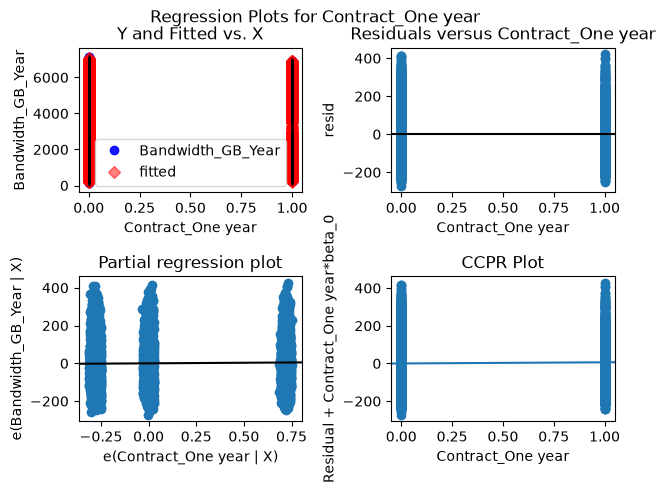

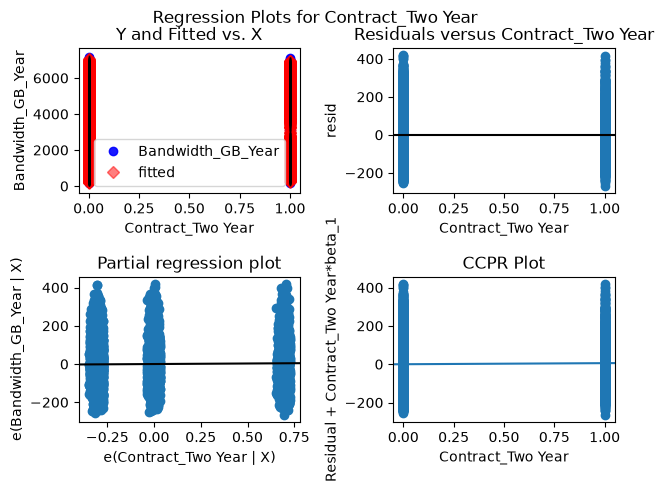

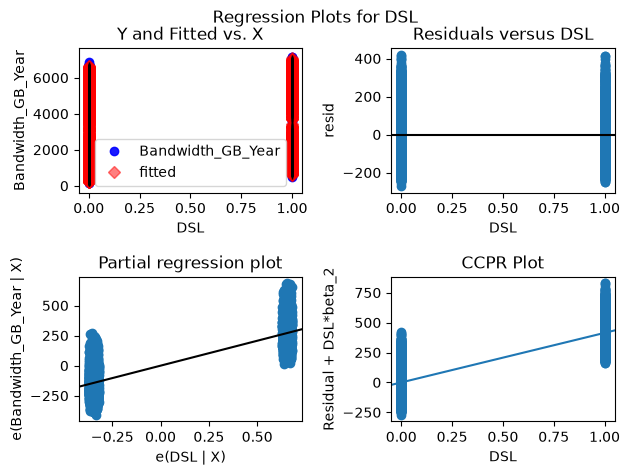

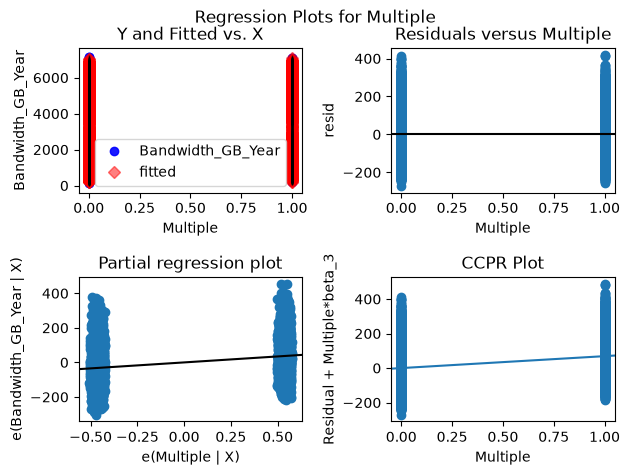

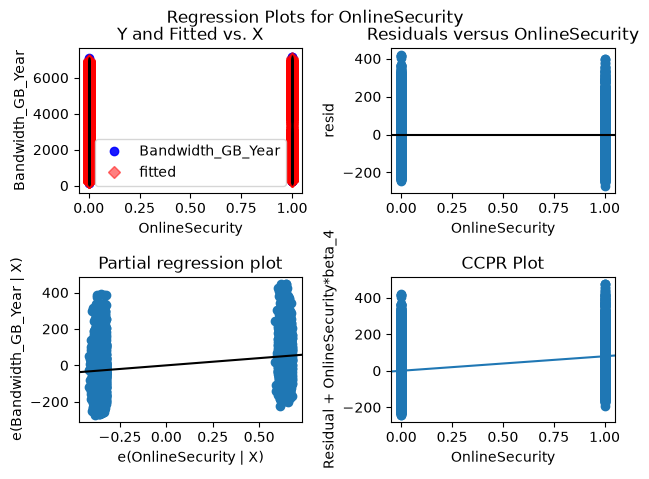

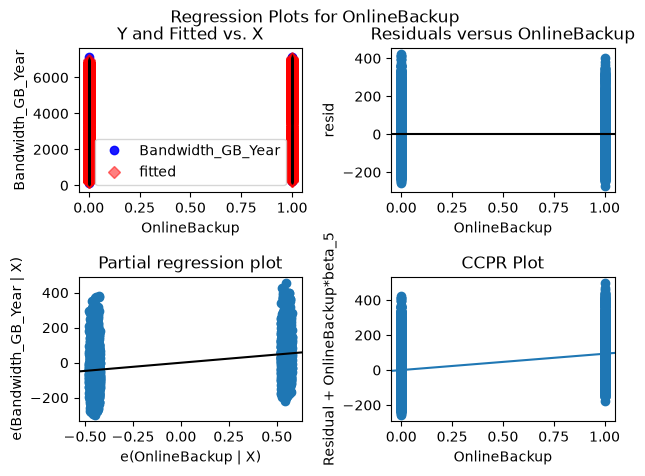

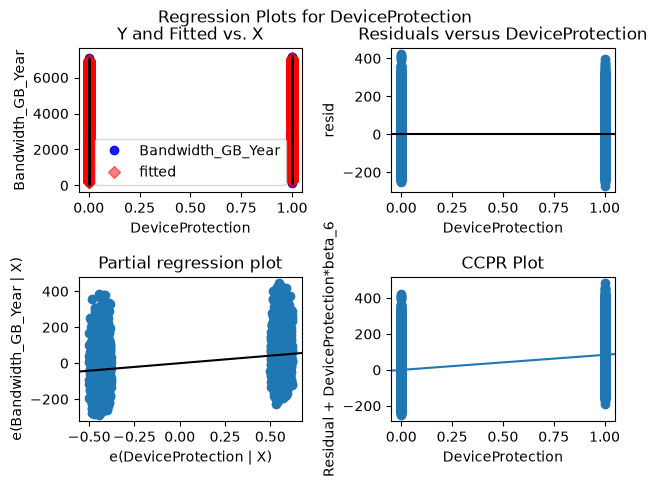

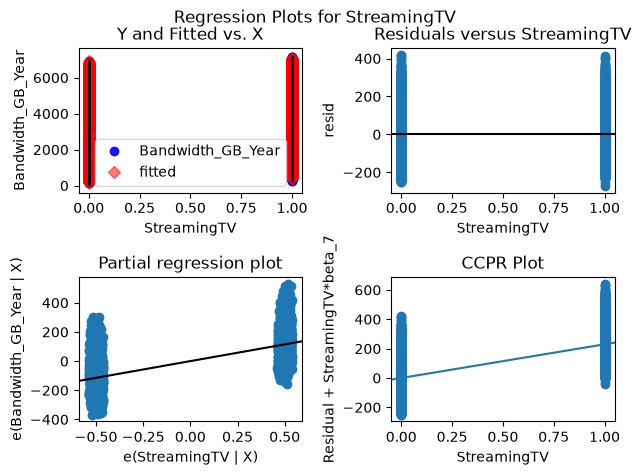

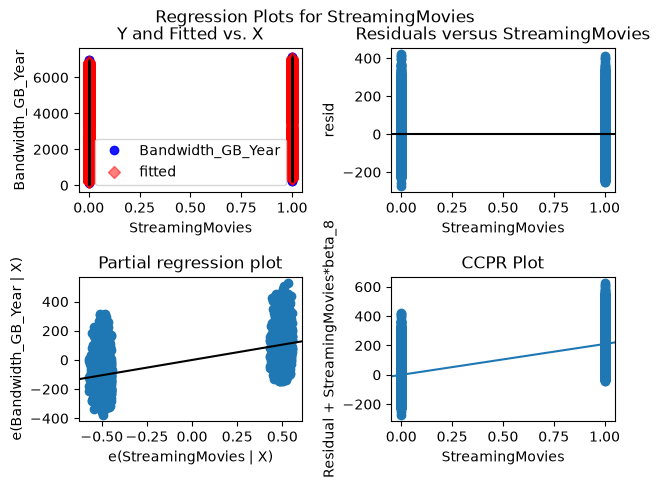

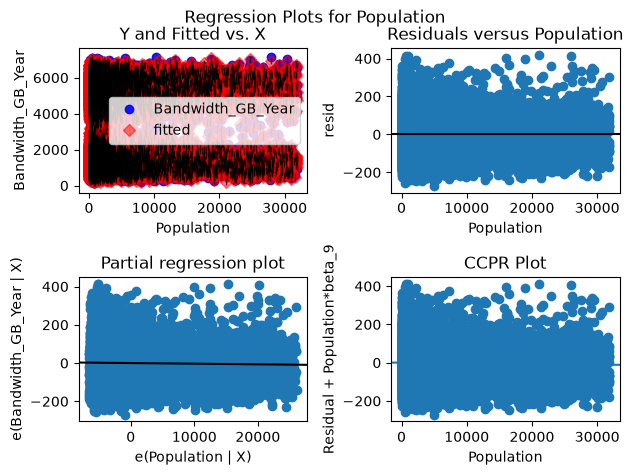

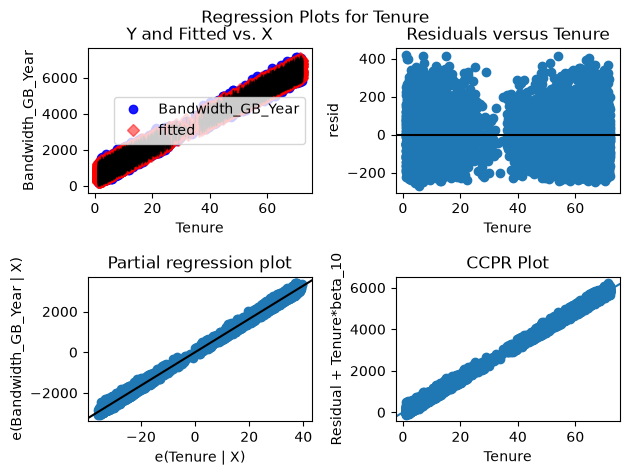

In [20]:
from statsmodels import graphics

for var in ["Contract_One year","Contract_Two Year","DSL","Multiple",
            "OnlineSecurity","OnlineBackup","DeviceProtection","StreamingTV",
            "StreamingMovies","Population","Tenure"]:
    graphics.regressionplots.plot_regress_exog(churn_mdl_final, var)

#### E3. Code

All relevant Python code for the implementation of this linear regression model has been provided above, as well as in the accompanying Jupyter notebook file: D208_Task1_MMorin_20240820.ipynb

### Part V: Data Summary and Implications

#### F1. Results

The regression equation for the reduced model can be expressed as follows:

Bandwidth_GB_Year = 67.2181 + 6.1142(Contract_One year) + 5.6205(Contract_Two Year) + 414.0815(DSL) + 69.0861(Multiple) + 79.4786(OnlineSecurity) + 93.4129(OnlineBackup) + 83.7021(DeviceProtection) + 229.5376(StreamingTV) + 210.0414(StreamingMovies) + -0.0003(Population) + 81.8506(Tenure)

The coefficients here indicate the change in the value of Bandwidth_GB_Year if all over variables are kept constant; specifically:
1. Customers with a one-year contract use 6.1142 GB per year more than those with month-to-month contracts;
2. Customers with a two-year contract use 5.6205 GB per year more than those with month-to-month contracts;
3. Customers with DSL show increased usage of 414.0815 GB;
4. Customers with multiple phone lines use 69.0861 GB more;
5. Customers with the online security package use 79.4786 GB more;
6. Customers with the online backup add-on use 93.4129 GB more;
7. Customers with device protection use 83.7021 GB more;
8. Customers with streaming TV use an additional 229.5376 GB;
9. Customers with streaming movies use an additional 210.0414 GB;
10. For each additional person living within a mile of the customer, annual bandwidth usage for that customer goes down by 0.0003 GB;
11. For each additional month the customer has with the ISP, their annual bandwidth usage increases by 81.8506 GB.

The model itself appears to be both statistically significant. The Prob (F-statistic) is 0.00, indicating that the regression model can be accepted to accurately describe the data. (Manikantan, 2024)  The R-squared value is 0.998, which is very high; this value measures the extent to which variance in the response variables can be explained by the explanatory variables in the model. R-squared can range from 0 to 1, so an r-squared value of 0.998 indicates that the explanatory variables can be said to strongly explain any variance within the response variable, Bandwidth_GB_Year. This indicates that the model can be considered very reliable when it comes to predicting the value of the response variable. (Bobbitt, 2019)

The model also has practical significance. Utilizing this model, the ISP could identifiy which of its customers are likely to use more bandwidth in a given year, based on a number of variables, including length of contract, type of internet service, and subscription to add-on services. The ISP could then determine which of its customers will place heavier bandwidth loads on its infastructure, allowing stakeholders to plan infastructure improvement projects or refocus its load balancing efforts.

As with any statistical analysis, the results from this model are not without their own limitations. The quality of the multiple linear regression model that was created above is reliant entirely on the quality of the data being used. Any issues within the data itself, such as incorrect data introduced during the data collection phase, would cause the model to be inaccurate and render the analysis useless. (Weedmark, 2018) Additionally, one must keep in mind one of the most oft-repeated warnings in the field of statistics: "correlation is not causality." The results of this model show only a correlation between variables - that is to say, that some sort of relationship exists between the explanatory and response variables utilized in the model. The existence of this correlation does not imply that there is a direct cause-and-effect relationship between the variables. For example, it would be inacccurate to say that being under a one-year contract with the ISP is a direct cause of higher bandwidth usage; rather, one could only state that a correlation exists between these variables. Any stakeholders that make use of this analysis must understand this distinction. (Learn Statistics Easily, 2023)

#### F2. Recommendations

The multiple linear regression model built above provides strong insights regarding which variables have a linear relationship with customer bandwidth usage. We can consider our research question to be satisfactorily answered by this multiple linear regression model; we've deteremined that customers who have one- or two-year contracts, DSL service, or any of the various add-on service packages such as online backups or streaming movies and television, seem to utilize more bandwidth per year than customers who do not fall into these groups. Additionally, customer tenure seems to be a strong driver of bandwidth usage. Based on these results, I would recommend that the ISP consider improving infrastructure in areas where there is strong customer interest in longer-term contracts, DSL services, and add-on packages, as well as areas where customers have high levels of tenure with the ISP; these areas are likely to show increased bandwidth usage and therefore would place higher data transfer loads on the ISP's services. 

### Part VI: Sources

#### H. Sources of Third-Party Code

Bobbitt, Zach. *How to Calculate VIF in Python.* Statology. July 20, 2022. https://www.statology.org/how-to-calculate-vif-in-python/

Bobbitt, Zach. *How to Create Subplots in Seaborn (With Examples)* Statology. September 28, 2021. https://www.statology.org/seaborn-subplots/

Matplotlib Documentation. *matplotlib.pyplot.subplots* Retrieved August 20, 2024 from https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.subplots.html

Seaborn Documentation. *Overview of seaborn plotting functions.* Retreived August 20, 2024 from https://seaborn.pydata.org/tutorial/function_overview.html

Statsmodels Documentation. *statsmodels.formula.api.ols* December 14, 2023. https://www.statsmodels.org/stable/generated/statsmodels.formula.api.ols.html#statsmodels.formula.api.ols

Statsmodels Documentation. *statsmodels.graphics.regressionplots.plot_regress_exog* December 14, 2023. https://www.statsmodels.org/stable/generated/statsmodels.graphics.regressionplots.plot_regress_exog.html

Statsmodels Documentation. *statsmodels.stats.outliers_influence.variance_inflation_factor* December 14, 2023. https://www.statsmodels.org/stable/generated/statsmodels.stats.outliers_influence.variance_inflation_factor.html

#### I. Sources

Bobbitt, Zach. *How to Calculate VIF in Python.* Statology. July 20, 2022. https://www.statology.org/how-to-calculate-vif-in-python/

Bobbit, Zach. *What is a Good R-squared Value?* Statology. February 24, 2019. https://www.statology.org/good-r-squared-value/

Learn Statistics Easily. *Correlation vs Causality: Understanding the Difference*. May 2, 2023. https://statisticseasily.com/correlation-vs-causality/

Manikantan, Aditya. *F-statistic: Understanding model significance using python*. Medium. September 11, 2021. https://medium.com/analytics-vidhya/f-statistic-understanding-model-significance-using-python-c1371980b796

Pandas Documentation. *Getting Started - Package Overview.* 2024. https://pandas.pydata.org/docs/getting_started/overview.html

Pennsylvania State University. *MLR Model Assumptions.* 2018. https://online.stat.psu.edu/stat462/node/145/

Pennsylvania State University. *Lesson 5: Multiple Linear Regression.* 2024. https://online.stat.psu.edu/stat501/lesson/5

Pennsylvania State University. *What is Multicolinearity?* 2024. https://online.stat.psu.edu/stat501/lesson/12/12.1

Ramkumar, Achyut. *A Beginner’s Guide to Stepwise Multiple Linear Regression* Medium. June 10, 2020. https://medium.com/analytics-vidhya/a-beginners-guide-to-stepwise-multiple-linear-regression-e81df82b9f9e

Seaborn Documentation. *An introduction to Seaborn.* 2024. https://seaborn.pydata.org/tutorial/introduction.html

Statsmodels Documentation. *statsmodels 0.14.1.* December 14, 2023. https://www.statsmodels.org/stable/index.html

Weedmark, David. *The Advantages & Disadvantages of a Multiple Regression Model*. Sciencing. March 13, 2018. https://sciencing.com/advantages-disadvantages-multiple-regression-model-12070171.html

WGU School of Information Technology. *R or Python* Retrieved March 3, 2024 from https://www.wgu.edu/online-it-degrees/programming-languages/r-or-python.html